In [2]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv("C:\EMI BOUNCE\emi_bounce_data.csv")
print(df.shape)
df.head()

(200400, 16)


,V_ACCOUNT_NUMBER,V_CUST_REF_CODE,SANCTIONED_LIMIT,CURRENT_OUTSTANDING,EMI_AMT,D_FIRST_DISBURSEMENT_DATE,LOAN_AGE_MONTHS,UTILIZATION_PERCENTAGE,LIMIT_AVAILABLE,AVG_BAL_PREV_MNTH,AVG_BAL_PREV_QTR,AVG_BAL_FY,CNT_MOV_1M,CNT_MOV_3M,CNT_MOV_6M,TARGET_BOUNCE
0,624019028384,CUST232787,"870,000.00","693,153.00","15,556.00",2024-09-30,24,79.67,"176,847.00","55,105.01","61,105.39","58,198.61",10,40,80.00,0
1,980964396631,CUST129409,"1,202,000.00","818,319.00","24,136.00",2024-11-30,22,68.08,"383,681.00","49,226.06",NaN,"75,594.04",7,12,27.00,0
2,357476931313,CUST252782,"328,000.00","186,086.00","10,766.00",2025-05-01,17,56.73,"141,914.00","92,816.52","120,731.35","151,184.90",12,43,90.00,0
3,303114735860,CUST254484,"746,000.00","677,140.00","8,567.00",2023-09-01,37,90.77,"68,860.00","6,171.11","6,889.24","6,052.35",5,16,41.00,0
4,368159815647,CUST166414,"1,167,000.00",0.00,"37,205.00",2023-10-01,36,0.00,"1,167,000.00","301,607.34","274,619.03","334,358.17",16,51,79.00,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200400 entries, 0 to 200399
Data columns (total 16 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   V_ACCOUNT_NUMBER           200400 non-null  int64  
 1   V_CUST_REF_CODE            200400 non-null  str    
 2   SANCTIONED_LIMIT           200400 non-null  float64
 3   CURRENT_OUTSTANDING        200400 non-null  float64
 4   EMI_AMT                    200400 non-null  float64
 5   D_FIRST_DISBURSEMENT_DATE  200400 non-null  str    
 6   LOAN_AGE_MONTHS            200400 non-null  int64  
 7   UTILIZATION_PERCENTAGE     199570 non-null  float64
 8   LIMIT_AVAILABLE            200400 non-null  float64
 9   AVG_BAL_PREV_MNTH          197395 non-null  float64
 10  AVG_BAL_PREV_QTR           196375 non-null  float64
 11  AVG_BAL_FY                 194557 non-null  float64
 12  CNT_MOV_1M                 200400 non-null  int64  
 13  CNT_MOV_3M                 200400 non-nu

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
V_ACCOUNT_NUMBER,"200,400.00","549,972,076,100.77","259,757,996,497.90","100,015,776,519.00","324,202,906,974.00","549,392,027,315.00","775,402,384,703.00","999,998,076,663.00"
SANCTIONED_LIMIT,"200,400.00","988,026.70","1,100,328.64","50,000.00","360,000.00","659,000.00","1,211,000.00","44,266,000.00"
CURRENT_OUTSTANDING,"200,400.00","599,720.80","770,657.29",0.00,"176,638.75","367,838.00","732,022.00","42,443,896.00"
EMI_AMT,"200,400.00","25,842.44","36,894.90",403.00,"7,522.00","14,960.00","29,960.25","1,270,562.00"
LOAN_AGE_MONTHS,"200,400.00",35.15,34.73,1.00,12.00,25.00,45.00,239.00
UTILIZATION_PERCENTAGE,"199,570.00",60.65,25.07,0.00,42.27,64.19,81.75,100.00
LIMIT_AVAILABLE,"200,400.00","388,305.90","564,931.29",0.00,"87,816.75","210,640.00","465,856.25","19,717,020.00"
AVG_BAL_PREV_MNTH,"197,395.00","141,355.72","351,647.71","-4,911,639.95","20,045.64","51,619.45","134,242.05","23,204,138.20"
AVG_BAL_PREV_QTR,"196,375.00","144,972.36","357,425.70",79.68,"21,212.53","53,890.96","137,875.41","26,488,770.50"
AVG_BAL_FY,"194,557.00","161,583.62","528,188.09",68.91,"22,045.84","56,705.64","147,231.15","83,082,741.20"


In [5]:
df["TARGET_BOUNCE"].value_counts()

TARGET_BOUNCE
0    186315
1     14085
Name: count, dtype: int64

# Data Claeaning 

In [6]:
df["V_ACCOUNT_NUMBER"] = df["V_ACCOUNT_NUMBER"].astype(str)
df["D_FIRST_DISBURSEMENT_DATE"] = pd.to_datetime(df["D_FIRST_DISBURSEMENT_DATE"])
df.dtypes

V_ACCOUNT_NUMBER                        str
V_CUST_REF_CODE                         str
SANCTIONED_LIMIT                    float64
CURRENT_OUTSTANDING                 float64
EMI_AMT                             float64
D_FIRST_DISBURSEMENT_DATE    datetime64[us]
LOAN_AGE_MONTHS                       int64
UTILIZATION_PERCENTAGE              float64
LIMIT_AVAILABLE                     float64
AVG_BAL_PREV_MNTH                   float64
AVG_BAL_PREV_QTR                    float64
AVG_BAL_FY                          float64
CNT_MOV_1M                            int64
CNT_MOV_3M                            int64
CNT_MOV_6M                          float64
TARGET_BOUNCE                         int64
dtype: object

In [7]:
print("duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("duplicate accounts after drop:", df["V_ACCOUNT_NUMBER"].duplicated().sum())
print(df.shape)

duplicate rows: 400
duplicate accounts after drop: 0
(200000, 16)


In [8]:
#fixing the missing values
# Utilization can be rebuilt exactly from two other columns
calc_util = df["CURRENT_OUTSTANDING"] / df["SANCTIONED_LIMIT"] * 100
print("max difference where present:",
      (calc_util - df["UTILIZATION_PERCENTAGE"]).abs().max())   
df["UTILIZATION_PERCENTAGE"] = df["UTILIZATION_PERCENTAGE"].fillna(calc_util.round(2))

# Flags for the rest
for c in ["AVG_BAL_PREV_MNTH", "AVG_BAL_PREV_QTR", "AVG_BAL_FY", "CNT_MOV_6M"]:
    df[c + "_MISSING"] = df[c].isna().astype(int)

df.isna().sum()

max difference where present: 0.005000000000009663


V_ACCOUNT_NUMBER                0
V_CUST_REF_CODE                 0
SANCTIONED_LIMIT                0
CURRENT_OUTSTANDING             0
EMI_AMT                         0
D_FIRST_DISBURSEMENT_DATE       0
LOAN_AGE_MONTHS                 0
UTILIZATION_PERCENTAGE          0
LIMIT_AVAILABLE                 0
AVG_BAL_PREV_MNTH            2999
AVG_BAL_PREV_QTR             4017
AVG_BAL_FY                   5832
CNT_MOV_1M                      0
CNT_MOV_3M                      0
CNT_MOV_6M                   2031
TARGET_BOUNCE                   0
AVG_BAL_PREV_MNTH_MISSING       0
AVG_BAL_PREV_QTR_MISSING        0
AVG_BAL_FY_MISSING              0
CNT_MOV_6M_MISSING              0
dtype: int64

In [9]:
#logic of the data 
checks = {
    "outstanding > sanctioned":       (df["CURRENT_OUTSTANDING"] > df["SANCTIONED_LIMIT"]).sum(),
    "utilization outside 0-100":      (~df["UTILIZATION_PERCENTAGE"].between(0, 100)).sum(),
    "EMI <= 0":                       (df["EMI_AMT"] <= 0).sum(),
    "loan age <= 0":                  (df["LOAN_AGE_MONTHS"] <= 0).sum(),
    "disbursement date in future":    (df["D_FIRST_DISBURSEMENT_DATE"] > "2026-09-30").sum(),
    "CNT_MOV_3M < CNT_MOV_1M":        (df["CNT_MOV_3M"] < df["CNT_MOV_1M"]).sum(),
    "CNT_MOV_6M < CNT_MOV_3M":        (df["CNT_MOV_6M"] < df["CNT_MOV_3M"]).sum(),
}
pd.Series(checks)

outstanding > sanctioned       0
utilization outside 0-100      0
EMI <= 0                       0
loan age <= 0                  0
disbursement date in future    0
CNT_MOV_3M < CNT_MOV_1M        0
CNT_MOV_6M < CNT_MOV_3M        0
dtype: int64

In [10]:
#negative balance 
print((df["AVG_BAL_PREV_MNTH"] < 0).sum())
df.loc[df["AVG_BAL_PREV_MNTH"] < 0, ["AVG_BAL_PREV_MNTH", "EMI_AMT", "TARGET_BOUNCE"]].head()

1200


,AVG_BAL_PREV_MNTH,EMI_AMT,TARGET_BOUNCE
79,"-40,338.55","11,492.00",0
132,"-146,844.95","12,843.00",0
559,"-53,688.76","15,130.00",0
717,"-18,886.11","21,880.00",0
844,"-9,760.24","18,978.00",0


In [11]:
#outliers
df["AVG_BAL_FY"].quantile([0.5, 0.9, 0.99, 0.999, 1.0])

0.50       56,714.01
0.90      350,094.84
0.99    1,600,138.40
1.00    5,351,630.97
1.00   83,082,741.20
Name: AVG_BAL_FY, dtype: float64

In [12]:
#outliers checkinng 
# How many values are extreme?
p999 = df["AVG_BAL_FY"].quantile(0.999)
extreme = df[df["AVG_BAL_FY"] > p999]
print("rows above 99.9th percentile:", len(extreme))

# Cross-check: FY balance vs quarterly balance
ratio = df["AVG_BAL_FY"] / df["AVG_BAL_PREV_QTR"]
print(ratio.describe())
print(ratio.quantile([0.5, 0.9, 0.99, 0.999]))

# Look at the worst rows
cols = ["AVG_BAL_PREV_MNTH", "AVG_BAL_PREV_QTR", "AVG_BAL_FY", "EMI_AMT", "TARGET_BOUNCE"]
df.sort_values("AVG_BAL_FY", ascending=False)[cols].head(10)

rows above 99.9th percentile: 195
count   190,285.00
mean          1.11
std           1.35
min           0.44
25%           0.92
50%           1.05
75%           1.20
max          68.53
dtype: float64
0.50    1.05
0.90    1.36
0.99    1.68
1.00   26.02
dtype: float64


,AVG_BAL_PREV_MNTH,AVG_BAL_PREV_QTR,AVG_BAL_FY,EMI_AMT,TARGET_BOUNCE
137213,"1,526,276.03","1,592,074.70","83,082,741.20","522,530.00",0
67162,"1,662,534.99","1,164,444.75","52,796,971.60","71,035.00",0
127041,"837,104.42","1,040,133.34","39,094,249.20","105,671.00",0
195168,"582,719.23","661,752.52","32,920,177.60","36,247.00",0
180904,"19,100,685.65","21,974,155.26","32,092,097.62","1,005,203.00",0
71218,"821,141.08","845,659.76","30,655,647.60","139,081.00",0
29715,"23,204,138.20","26,488,770.50","29,287,796.90","600,966.00",0
91376,"18,446,025.22","18,402,979.31","29,261,793.79","406,505.00",0
7071,"758,866.82","728,317.33","27,470,876.80","14,302.00",0
185055,"508,620.03","531,119.36","25,941,485.20","36,182.00",0


In [13]:
ratio = df["AVG_BAL_FY"] / df["AVG_BAL_PREV_QTR"]

# Is there a clear gap between normal and abnormal ratios?
print(ratio.quantile([0.5, 0.99, 0.999]))
print("ratio between 3 and 20:", ratio.between(3, 20).sum())
print("ratio above 20:", (ratio > 20).sum())

0.50    1.05
0.99    1.68
1.00   26.02
dtype: float64
ratio between 3 and 20: 0
ratio above 20: 194


In [14]:
bad = (ratio > 10) & (df["AVG_BAL_PREV_QTR"] > 0)
print("suspect FY values:", bad.sum())

df["AVG_BAL_FY_ERROR"] = bad.astype(int)      # keep a record of what we changed
df.loc[bad, "AVG_BAL_FY"] = np.nan            # treat as missing, filled later with the rest
df["AVG_BAL_FY"].quantile([0.5, 0.99, 0.999, 1.0])

suspect FY values: 194


0.50       56,612.14
0.99    1,545,479.55
1.00    4,790,658.08
1.00   32,092,097.62
Name: AVG_BAL_FY, dtype: float64

# EDA (Exploratory Data Analysis)

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

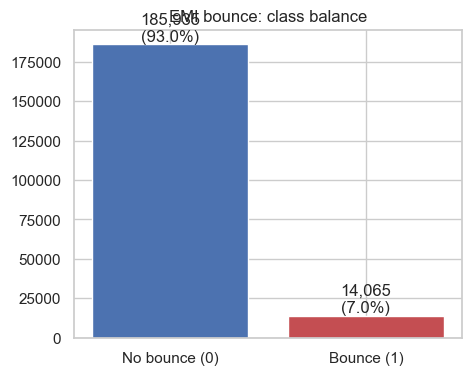

In [16]:
fig, ax = plt.subplots(figsize=(5, 4))
counts = df["TARGET_BOUNCE"].value_counts().sort_index()
ax.bar(["No bounce (0)", "Bounce (1)"], counts.values, color=["b", "r"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", va="bottom")
ax.set_title("EMI bounce: class balance")
plt.show()

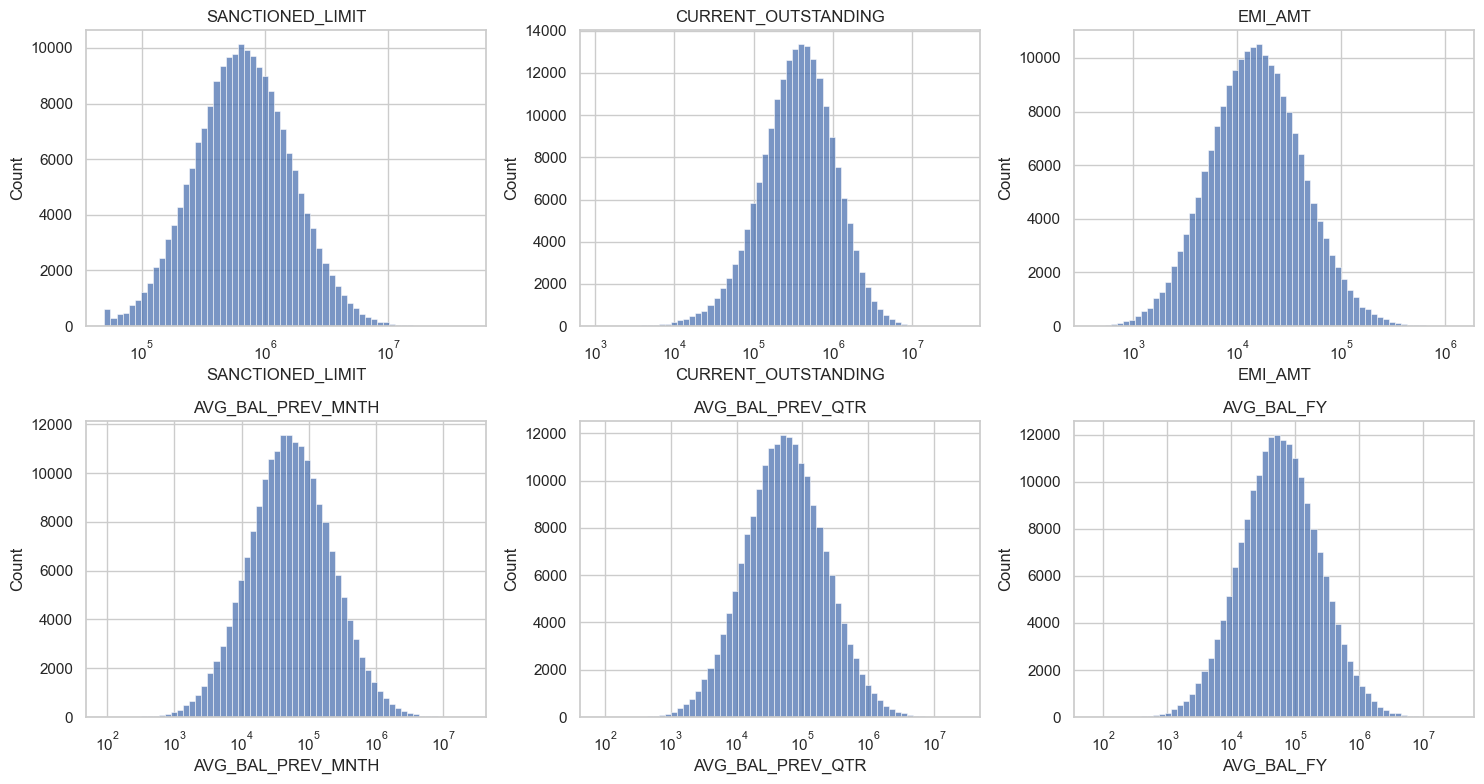

In [17]:
money = ["SANCTIONED_LIMIT", "CURRENT_OUTSTANDING", "EMI_AMT",
         "AVG_BAL_PREV_MNTH", "AVG_BAL_PREV_QTR", "AVG_BAL_FY"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), money):
    sns.histplot(df.loc[df[c] > 0, c], bins=60, log_scale=True, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

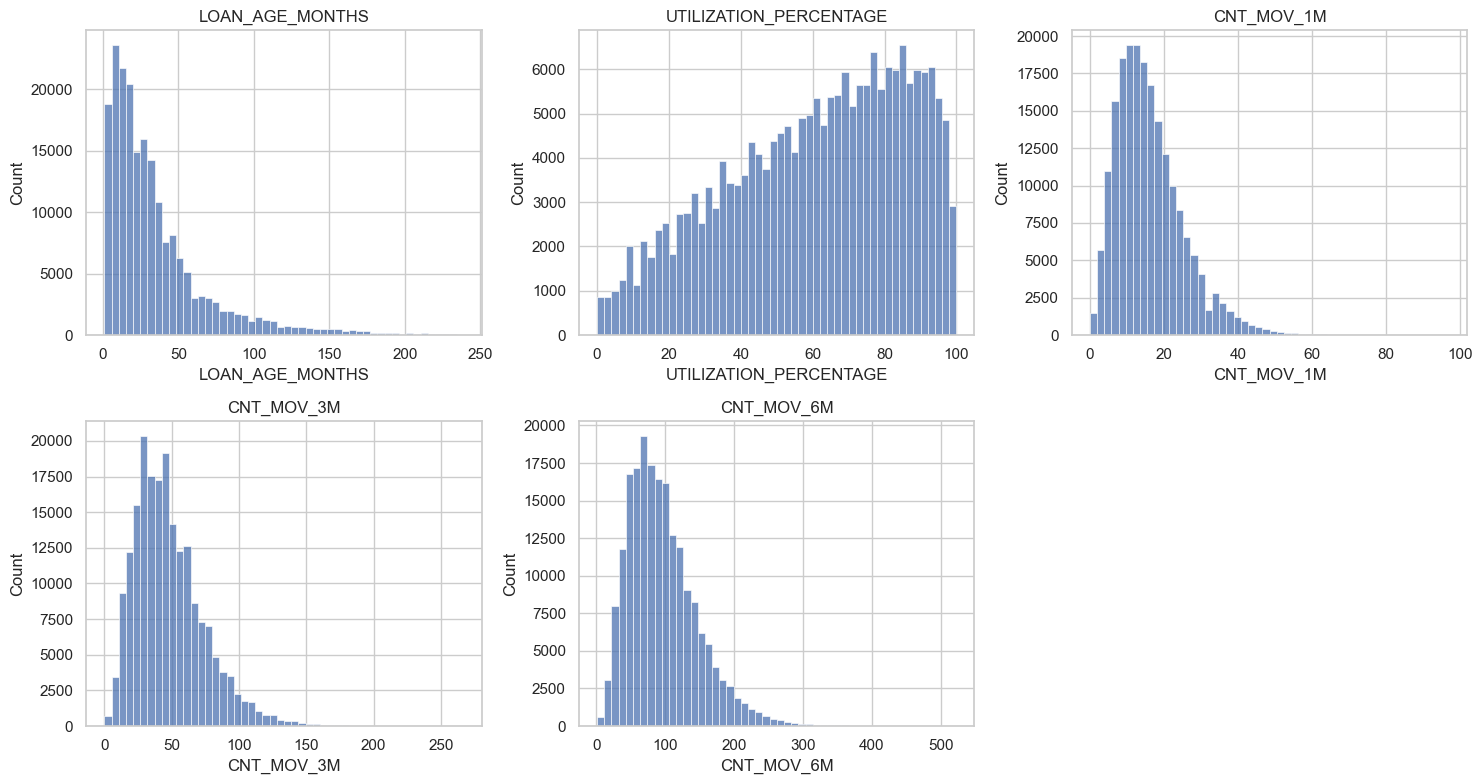

In [18]:
others = ["LOAN_AGE_MONTHS", "UTILIZATION_PERCENTAGE", "CNT_MOV_1M", "CNT_MOV_3M", "CNT_MOV_6M"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), others):
    sns.histplot(df[c].dropna(), bins=50, ax=ax)
    ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

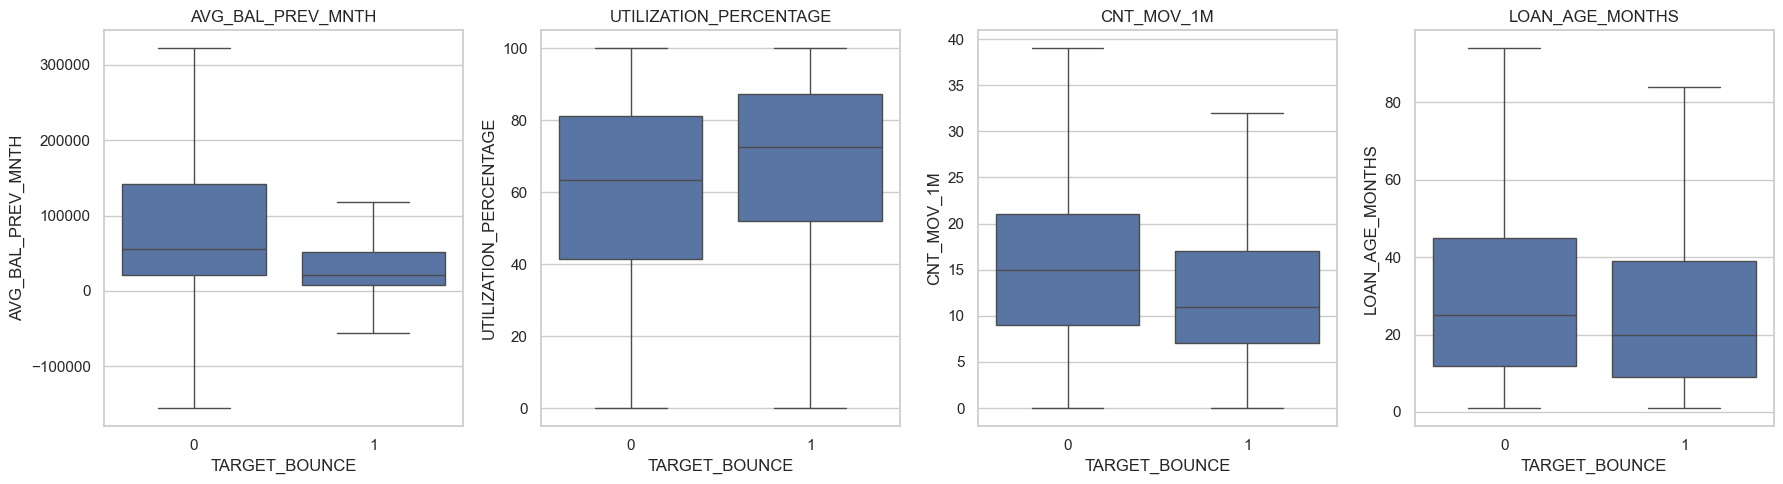

,AVG_BAL_PREV_MNTH,UTILIZATION_PERCENTAGE,CNT_MOV_1M,LOAN_AGE_MONTHS
TARGET_BOUNCE,,,,
0,"55,217.10",63.50,15.00,25.00
1,"20,624.70",72.60,11.00,20.00


In [19]:
cols = ["AVG_BAL_PREV_MNTH", "UTILIZATION_PERCENTAGE", "CNT_MOV_1M", "LOAN_AGE_MONTHS"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, c in zip(axes, cols):
    sns.boxplot(data=df, x="TARGET_BOUNCE", y=c, ax=ax, showfliers=False)
    ax.set_title(c)
plt.tight_layout()
plt.show()

df.groupby("TARGET_BOUNCE")[cols].median().round(1)

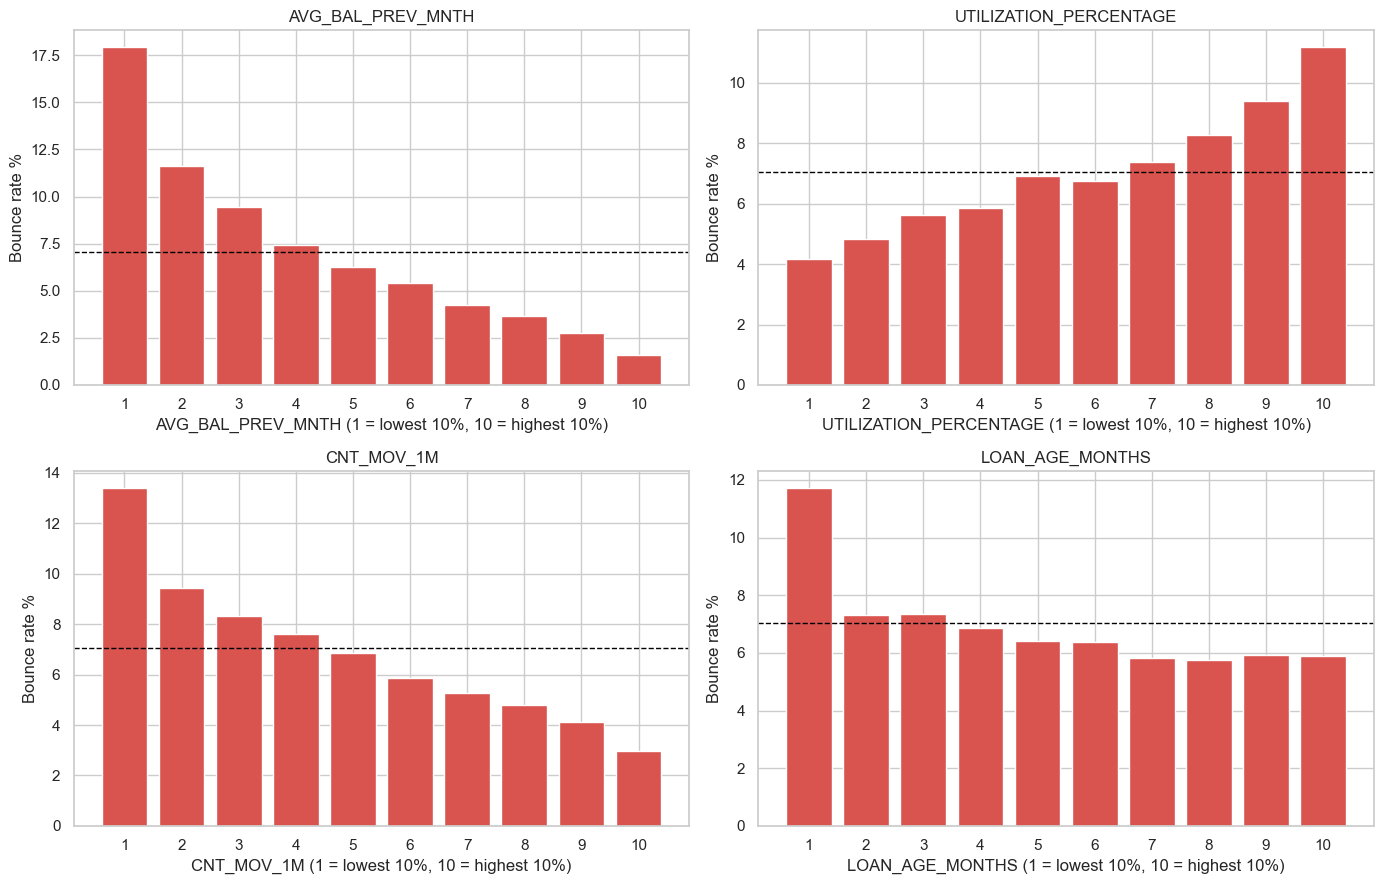

In [20]:
def bounce_by_decile(col, ax):
    bins = pd.qcut(df[col], 10, duplicates="drop")
    rate = df.groupby(bins, observed=True)["TARGET_BOUNCE"].mean() * 100
    ax.bar(range(len(rate)), rate.values, color="#D9534F")
    ax.axhline(df["TARGET_BOUNCE"].mean() * 100, color="black", ls="--", lw=1)
    ax.set_xticks(range(len(rate)))
    ax.set_xticklabels(range(1, len(rate) + 1))
    ax.set_xlabel(f"{col} (1 = lowest 10%, 10 = highest 10%)")
    ax.set_ylabel("Bounce rate %")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, c in zip(axes.ravel(), ["AVG_BAL_PREV_MNTH", "UTILIZATION_PERCENTAGE",
                                "CNT_MOV_1M", "LOAN_AGE_MONTHS"]):
    bounce_by_decile(c, ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

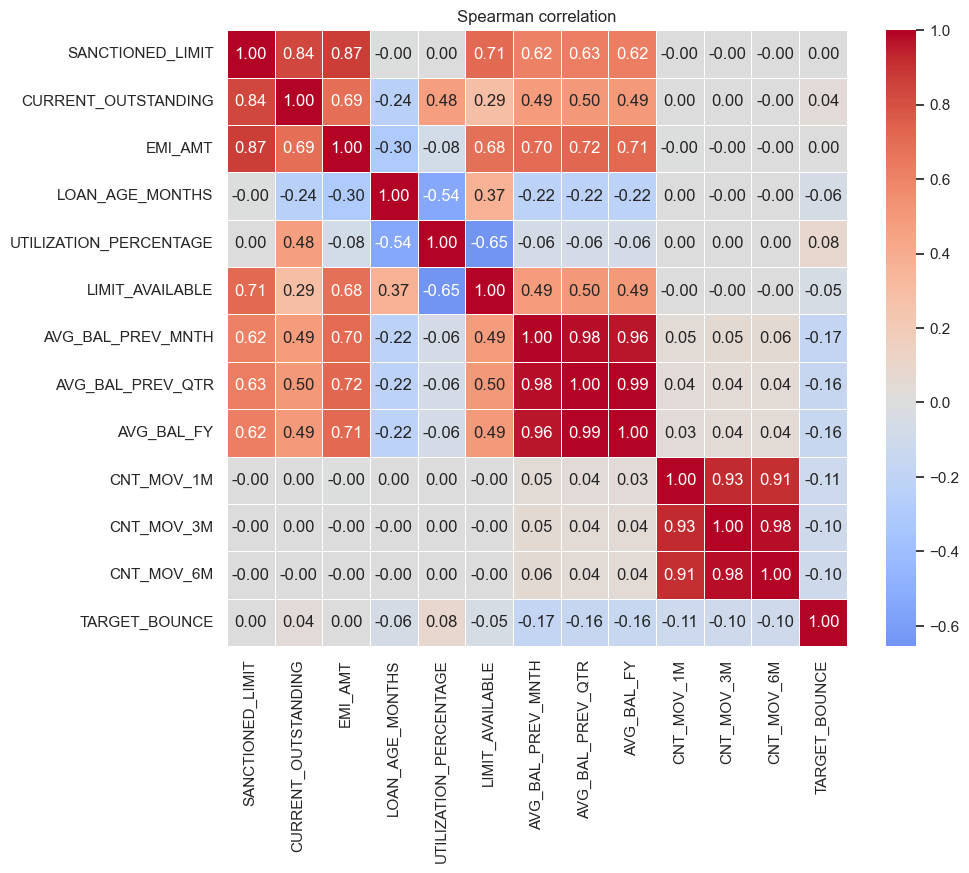

AVG_BAL_PREV_MNTH        -0.17
AVG_BAL_PREV_QTR         -0.16
AVG_BAL_FY               -0.16
CNT_MOV_1M               -0.11
CNT_MOV_3M               -0.10
CNT_MOV_6M               -0.10
LOAN_AGE_MONTHS          -0.06
LIMIT_AVAILABLE          -0.05
SANCTIONED_LIMIT          0.00
EMI_AMT                   0.00
CURRENT_OUTSTANDING       0.04
UTILIZATION_PERCENTAGE    0.08
Name: TARGET_BOUNCE, dtype: float64

In [21]:
num_cols = ["SANCTIONED_LIMIT", "CURRENT_OUTSTANDING", "EMI_AMT", "LOAN_AGE_MONTHS",
            "UTILIZATION_PERCENTAGE", "LIMIT_AVAILABLE", "AVG_BAL_PREV_MNTH",
            "AVG_BAL_PREV_QTR", "AVG_BAL_FY", "CNT_MOV_1M", "CNT_MOV_3M",
            "CNT_MOV_6M", "TARGET_BOUNCE"]

corr = df[num_cols].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Spearman correlation")
plt.show()

corr["TARGET_BOUNCE"].drop("TARGET_BOUNCE").sort_values()

# Feature Engineering 

In [22]:
d = df.copy()

d["BAL_TO_EMI"]      = d["AVG_BAL_PREV_MNTH"] / d["EMI_AMT"]
d["EMI_TO_SANCTION"] = d["EMI_AMT"] / d["SANCTIONED_LIMIT"]
d["BAL_TREND"]       = d["AVG_BAL_PREV_MNTH"] / d["AVG_BAL_PREV_QTR"].where(d["AVG_BAL_PREV_QTR"] > 0)
d["MOV_MOMENTUM"]    = (d["CNT_MOV_1M"] * 3) / d["CNT_MOV_3M"].replace(0, np.nan)
d["EARLY_LOAN"]      = (d["LOAN_AGE_MONTHS"] < 6).astype(int)

In [23]:
eng = ["BAL_TO_EMI", "EMI_TO_SANCTION", "BAL_TREND", "MOV_MOMENTUM", "EARLY_LOAN"]
d[eng + ["TARGET_BOUNCE"]].corr(method="spearman")["TARGET_BOUNCE"].sort_values()

# bounce rate by decile for BAL_TO_EMI
b = pd.qcut(d["BAL_TO_EMI"], 10, duplicates="drop")
(d.groupby(b, observed=True)["TARGET_BOUNCE"].mean() * 100).round(1)

BAL_TO_EMI
(-28.129, 0.992]    25.30
(0.992, 1.527]      13.40
(1.527, 2.08]        9.10
(2.08, 2.706]        6.80
(2.706, 3.466]       5.10
(3.466, 4.421]       3.80
(4.421, 5.737]       3.00
(5.737, 7.788]       2.00
(7.788, 11.859]      1.20
(11.859, 288.519]    0.60
Name: TARGET_BOUNCE, dtype: float64

# Train/test split and the first models 

In [24]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# 1. Clean up infinities from the ratio features, then pick the feature list
d = d.replace([np.inf, -np.inf], np.nan)

features = ["SANCTIONED_LIMIT", "CURRENT_OUTSTANDING", "EMI_AMT", "LOAN_AGE_MONTHS",
            "UTILIZATION_PERCENTAGE", "LIMIT_AVAILABLE",
            "AVG_BAL_PREV_MNTH", "AVG_BAL_PREV_QTR", "AVG_BAL_FY",
            "CNT_MOV_1M", "CNT_MOV_3M", "CNT_MOV_6M",
            "BAL_TO_EMI", "EMI_TO_SANCTION", "BAL_TREND", "MOV_MOMENTUM", "EARLY_LOAN"]

X = d[features]
y = d["TARGET_BOUNCE"]
groups = d["V_CUST_REF_CODE"]

# 2. Stratified + grouped split (take one of 5 folds as the 20% test set)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("train:", X_train.shape, "bounce rate:", round(y_train.mean() * 100, 2))
print("test: ", X_test.shape,  "bounce rate:", round(y_test.mean() * 100, 2))
print("customers in both sets:",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))   

train: (159999, 17) bounce rate: 7.03
test:  (40001, 17) bounce rate: 7.03
customers in both sets: 0


In [25]:
# 3. A helper that scores any model with our three metrics
def evaluate(name, model):
    p = model.predict_proba(X_test)[:, 1]
    roc = roc_auc_score(y_test, p)
    pr = average_precision_score(y_test, p)
    top20 = np.argsort(-p)[: int(0.2 * len(p))]
    capture = y_test.values[top20].sum() / y_test.sum()
    print(f"{name:25s} ROC-AUC {roc:.3f} | PR-AUC {pr:.3f} | top-20% captures {capture:.1%} of bounces")

In [26]:
# 4. Model 1: Logistic Regression (the simple baseline)
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

logreg = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("log",    FunctionTransformer(signed_log)),
    ("scale",  StandardScaler()),
    ("model",  LogisticRegression(class_weight="balanced", max_iter=1000)),
])
logreg.fit(X_train, y_train)
evaluate("Logistic Regression", logreg)

# 5. Model 2: Gradient Boosting (handles missing values on its own)
gb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)
evaluate("Gradient Boosting", gb)

Logistic Regression       ROC-AUC 0.809 | PR-AUC 0.286 | top-20% captures 61.2% of bounces
Gradient Boosting         ROC-AUC 0.809 | PR-AUC 0.288 | top-20% captures 61.4% of bounces


In [27]:
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("model",  RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=50,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42)),
])
rf.fit(X_train, y_train)
evaluate("Random Forest", rf)

Random Forest             ROC-AUC 0.807 | PR-AUC 0.280 | top-20% captures 61.3% of bounces


# cross validation 

In [28]:
!pip install xgboost lightgbm

Defaulting to user installation because normal site-packages is not writeable


In [29]:
from sklearn.model_selection import cross_validate
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

groups_train = groups.iloc[train_idx]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7)

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()    # about 13

models = {
    "Logistic Regression": logreg,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             subsample=0.8, colsample_bytree=0.8,
                             scale_pos_weight=pos_weight, eval_metric="aucpr",
                             n_jobs=-1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                               min_child_samples=100, subsample=0.8, colsample_bytree=0.8,
                               scale_pos_weight=pos_weight, n_jobs=-1,
                               random_state=42, verbose=-1),
}

rows = []
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, groups=groups_train,
                       scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
                       n_jobs=1)
    rows.append({"model": name,
                 "ROC-AUC": r["test_roc_auc"].mean(), "ROC std": r["test_roc_auc"].std(),
                 "PR-AUC": r["test_pr_auc"].mean(),   "PR std": r["test_pr_auc"].std()})

pd.DataFrame(rows).round(4).sort_values("PR-AUC", ascending=False)

,model,ROC-AUC,ROC std,PR-AUC,PR std
3,XGBoost,0.81,0.00,0.30,0.01
4,LightGBM,0.81,0.00,0.30,0.00
0,Logistic Regression,0.81,0.00,0.30,0.01
2,Gradient Boosting,0.81,0.00,0.29,0.00
1,Random Forest,0.81,0.00,0.29,0.00


In [30]:
pd.options.display.float_format = "{:.4f}".format
res = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False)
res

,model,ROC-AUC,ROC std,PR-AUC,PR std
3,XGBoost,0.8120,0.0026,0.2959,0.0055
4,LightGBM,0.8113,0.0022,0.2953,0.0033
0,Logistic Regression,0.8132,0.0019,0.2951,0.0064
2,Gradient Boosting,0.8107,0.0019,0.2906,0.0043
1,Random Forest,0.8097,0.0026,0.2862,0.0047


# Tune the LightGBM

In [31]:
import time
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV
from lightgbm import LGBMClassifier

# 50,000-row sample of the training data (same as before)
rng = np.random.default_rng(0)
idx = rng.choice(len(X_train), size=50_000, replace=False)
Xs, ys, gs = X_train.iloc[idx], y_train.iloc[idx], groups_train.iloc[idx]

print("sample:", Xs.shape, "| bounce rate:", round(ys.mean() * 100, 2), "%")

sample: (50000, 17) | bounce rate: 7.04 %


In [32]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
import time 

param_dist = {
    "n_estimators":      randint(150, 500),
    "learning_rate":     uniform(0.02, 0.10),     # 0.02 to 0.12
    "num_leaves":        randint(8, 48),
    "min_child_samples": randint(50, 300),
    "subsample":         uniform(0.6, 0.4),       # 0.6 to 1.0
    "colsample_bytree":  uniform(0.6, 0.4),
    "reg_lambda":        uniform(0, 10),
}

base = LGBMClassifier(subsample_freq=1, scale_pos_weight=pos_weight,
                      n_jobs=-1, random_state=42, verbose=-1)

search = RandomizedSearchCV(
    base, param_dist, n_iter=15, scoring="average_precision",
    cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=7),
    random_state=42, n_jobs=1, verbose=1)

t0 = time.time()
search.fit(Xs, ys, groups=gs)          # sample of 50,000 rows, same as before
print(f"done in {time.time() - t0:.0f}s")
print("best CV PR-AUC:", round(search.best_score_, 4))
search.best_params_

Fitting 3 folds for each of 15 candidates, totalling 45 fits
done in 57s
best CV PR-AUC: 0.2769


{'colsample_bytree': np.float64(0.6783931449676581),
 'learning_rate': np.float64(0.024522728891053808),
 'min_child_samples': 89,
 'n_estimators': 362,
 'num_leaves': 23,
 'reg_lambda': np.float64(7.473201101373808),
 'subsample': np.float64(0.815876852955632)}

In [33]:
# 1. Tuned LightGBM on full training data
best = search.best_estimator_
best.fit(X_train, y_train)
evaluate("LightGBM (tuned)", best)

# 2. Original LightGBM on full training data
lgbm_orig = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                           min_child_samples=100, subsample=0.8, colsample_bytree=0.8,
                           scale_pos_weight=pos_weight, n_jobs=-1,
                           random_state=42, verbose=-1)
lgbm_orig.fit(X_train, y_train)
evaluate("LightGBM (original)", lgbm_orig)

# 3. The baseline for reference
evaluate("Logistic Regression", logreg)

LightGBM (tuned)          ROC-AUC 0.810 | PR-AUC 0.291 | top-20% captures 61.2% of bounces
LightGBM (original)       ROC-AUC 0.810 | PR-AUC 0.293 | top-20% captures 61.6% of bounces
Logistic Regression       ROC-AUC 0.809 | PR-AUC 0.286 | top-20% captures 61.2% of bounces


# Choose the threshold

In [34]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix

final = lgbm_orig
p = final.predict_proba(X_test)[:, 1]

rows = []
for pct in [5, 10, 15, 20, 30, 40, 50]:
    cut = np.quantile(p, 1 - pct / 100)          # score of the customer at that cut-off
    flag = (p >= cut).astype(int)
    tp = ((flag == 1) & (y_test.values == 1)).sum()
    rows.append({
        "flag top %": pct,
        "customers flagged": int(flag.sum()),
        "bouncers caught": int(tp),
        "recall %": round(tp / y_test.sum() * 100, 1),
        "precision %": round(tp / flag.sum() * 100, 1),
        "lift (x random)": round((tp / flag.sum()) / y_test.mean(), 2),
    })
pd.DataFrame(rows)

,flag top %,customers flagged,bouncers caught,recall %,precision %,lift (x random)
0,5,2001,744,26.4000,37.2000,5.2900
1,10,4001,1170,41.6000,29.2000,4.1600
2,15,6001,1500,53.3000,25.0000,3.5500
3,20,8001,1733,61.6000,21.7000,3.0800
4,30,12001,2074,73.7000,17.3000,2.4600
5,40,16001,2314,82.3000,14.5000,2.0600
6,50,20001,2482,88.2000,12.4000,1.7600


In [35]:
for pct in [10, 20, 30]:
    print(f"top {pct}% starts at score {np.quantile(p, 1 - pct/100):.3f}")

top 10% starts at score 0.736
top 20% starts at score 0.609
top 30% starts at score 0.498


# Explain the model with SHAP

In [36]:
!pip install shap

Defaulting to user installation because normal site-packages is not writeable


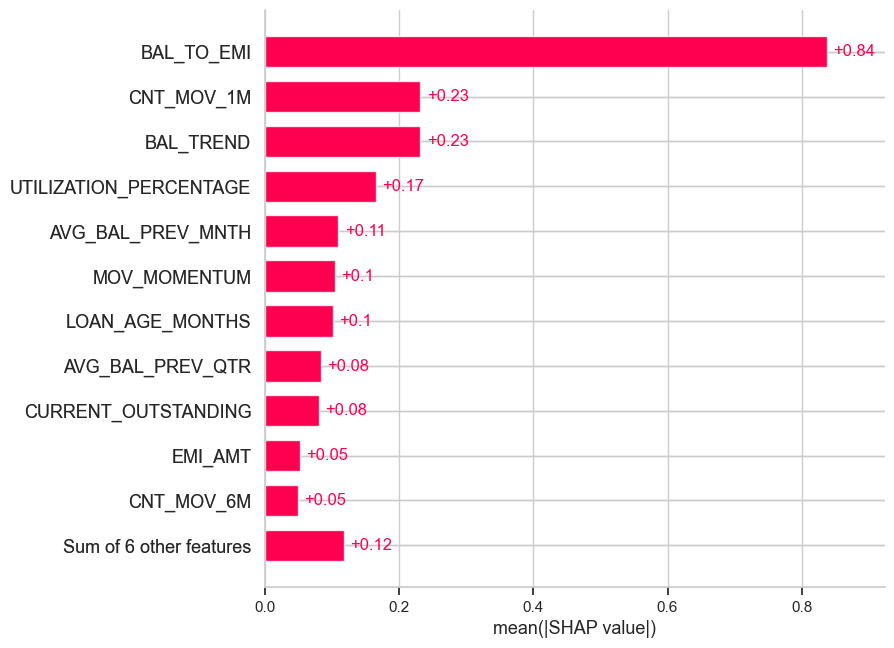

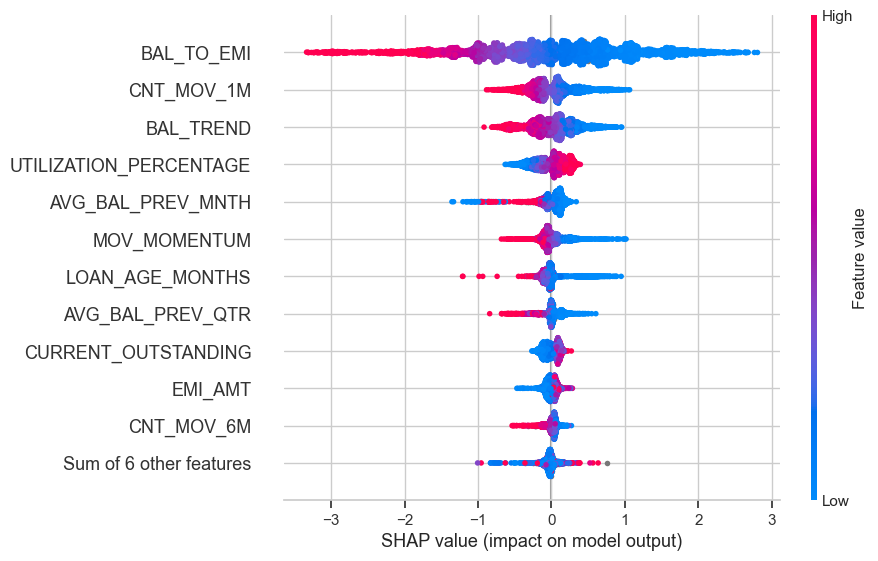

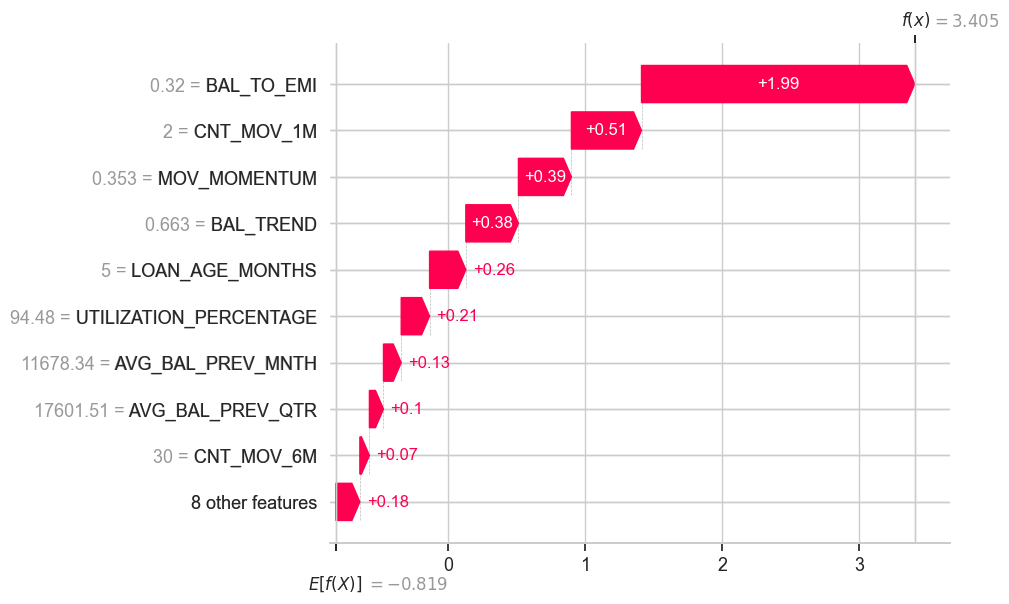

In [37]:
import shap

sample = X_test.sample(5000, random_state=1)
explainer = shap.TreeExplainer(lgbm_orig)
sv = explainer(sample)
if sv.values.ndim == 3:          # some versions return one set per class
    sv = sv[:, :, 1]

# Chart 1: which features matter most overall
shap.plots.bar(sv, max_display=12)

# Chart 2: how each feature pushes the risk
shap.plots.beeswarm(sv, max_display=12)

# Chart 3: the explanation for ONE customer
i = int(np.argmax(lgbm_orig.predict_proba(sample)[:, 1]))     # the riskiest customer in the sample
shap.plots.waterfall(sv[i])

In [38]:
flag = p >= 0.609
print("customers flagged:", flag.sum())
print("actual bounce rate among them:", round(y_test.values[flag].mean() * 100, 1), "%")

customers flagged: 8017
actual bounce rate among them: 21.7 %


# saving the model 

In [39]:
import joblib
joblib.dump({"model": lgbm_orig, "features": features, "cutoff": 0.609},
            "emi_bounce_lgbm.pkl")

['emi_bounce_lgbm.pkl']

In [40]:
# 1. Actual bounce rate among flagged customers
flag = p >= 0.609
print("customers flagged:", flag.sum())
print("actual bounce rate among them:", round(y_test.values[flag].mean() * 100, 1), "%")

# 2. Save the final model, its feature list and the cut-off
import joblib
joblib.dump({"model": lgbm_orig, "features": features, "cutoff": 0.609},
            "emi_bounce_lgbm.pkl")

customers flagged: 8017
actual bounce rate among them: 21.7 %


['emi_bounce_lgbm.pkl']

In [41]:
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve

# Hold out one customer-grouped slice of training data just for calibration
cal_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=3)
fit_i, cal_i = next(cal_cv.split(X_train, y_train, groups_train))

m = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                   min_child_samples=100, subsample=0.8, colsample_bytree=0.8,
                   scale_pos_weight=pos_weight, n_jobs=-1, random_state=42, verbose=-1)
m.fit(X_train.iloc[fit_i], y_train.iloc[fit_i])

# Learn the mapping: raw score -> real bounce rate
iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(m.predict_proba(X_train.iloc[cal_i])[:, 1], y_train.iloc[cal_i])

# Apply to the test set
p_raw = m.predict_proba(X_test)[:, 1]
p_cal = iso.predict(p_raw)

print("average predicted (raw):       ", round(p_raw.mean() * 100, 1), "%")
print("average predicted (calibrated):", round(p_cal.mean() * 100, 1), "%")
print("actual bounce rate:            ", round(y_test.mean() * 100, 1), "%")

average predicted (raw):        35.8 %
average predicted (calibrated): 7.0 %
actual bounce rate:             7.0 %


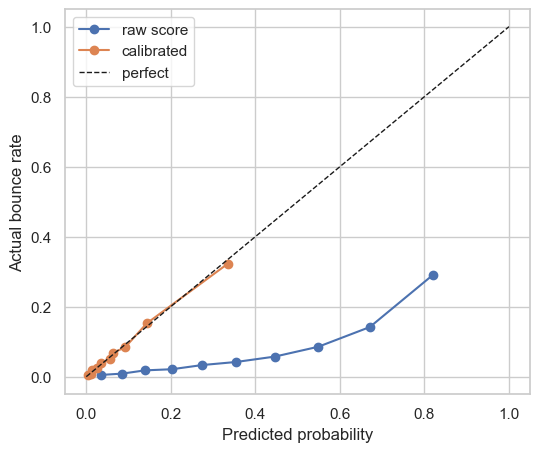

In [42]:
fig, ax = plt.subplots(figsize=(6, 5))
for label, scores in [("raw score", p_raw), ("calibrated", p_cal)]:
    frac, mean_pred = calibration_curve(y_test, scores, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", label=label)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Actual bounce rate")
ax.legend()
plt.show()

In [43]:
import joblib

# Cut-off in both units: the raw score (0.609) and its calibrated probability
cut_raw = 0.609
cut_cal = float(iso.predict([cut_raw])[0])
print("calibrated probability at the top-20% cut-off:", round(cut_cal * 100, 1), "%")

joblib.dump({"model": m, "calibrator": iso, "features": features,
             "cutoff_raw": cut_raw, "cutoff_prob": cut_cal},
            "emi_bounce_final.pkl")

calibrated probability at the top-20% cut-off: 11.4 %


['emi_bounce_final.pkl']

In [44]:
import sys, os

folder = r"C:\EMI BOUNCE"
print(os.path.exists(folder))                      # should print True
print([f for f in os.listdir(folder) if f.endswith(".py")])   # should list score_accounts.py

sys.path.append(folder)
from score_accounts import score

True
['app.py', 'run_monthly.py', 'score_accounts.py']


In [45]:
print(os.getcwd())

C:\Users\SUMAN


In [46]:
import joblib, numpy as np

bundle = {
    "model": m,
    "calibrator": iso,
    "features": features,
    "cutoff_raw": 0.609,                              # top 20%
    "cutoff_high": float(np.quantile(p_raw, 0.90)),   # top 10%
}
joblib.dump(bundle, os.path.join(folder, "emi_bounce_final.pkl"))
print("saved. top-10% cut-off:", round(bundle["cutoff_high"], 3))

saved. top-10% cut-off: 0.738


In [47]:
import joblib, pandas as pd

bundle = joblib.load(os.path.join(folder, "emi_bounce_final.pkl"))
new_accounts = pd.read_csv(os.path.join(folder, "emi_bounce_data.csv")).drop(columns="TARGET_BOUNCE")

scored = score(new_accounts, bundle)
scored.head(10)

,V_ACCOUNT_NUMBER,V_CUST_REF_CODE,EMI_AMT,AVG_BAL_PREV_MNTH,BAL_TO_EMI,RISK_SCORE,BOUNCE_PROBABILITY,RISK_TIER,ACTION,SCORING_DATE
0,926462460616,CUST189686,28582.0000,2572.7200,0.0900,0.9763,1.0000,HIGH,Call before due date,2026-10-15
1,694284650904,CUST229081,22213.0000,5688.0400,0.2561,0.9747,1.0000,HIGH,Call before due date,2026-10-15
2,113183280225,CUST122472,14337.0000,5670.7200,0.3955,0.9740,1.0000,HIGH,Call before due date,2026-10-15
3,863104237924,CUST161699,8089.0000,2954.4000,0.3652,0.9734,1.0000,HIGH,Call before due date,2026-10-15
4,881017088696,CUST227326,5888.0000,1230.6600,0.2090,0.9709,1.0000,HIGH,Call before due date,2026-10-15
5,834536859704,CUST163974,24070.0000,5148.1900,0.2139,0.9694,1.0000,HIGH,Call before due date,2026-10-15
6,134458023743,CUST266358,8026.0000,2069.8500,0.2579,0.9688,1.0000,HIGH,Call before due date,2026-10-15
7,177299742846,CUST146392,4916.0000,1873.5400,0.3811,0.9688,1.0000,HIGH,Call before due date,2026-10-15
8,139336626559,CUST218271,7345.0000,2008.6500,0.2735,0.9685,1.0000,HIGH,Call before due date,2026-10-15
9,293006730839,CUST222005,36477.0000,11678.3400,0.3202,0.9678,0.9699,HIGH,Call before due date,2026-10-15


In [48]:
print(scored["RISK_TIER"].value_counts())
print((scored["RISK_TIER"].value_counts(normalize=True) * 100).round(1))

scored.to_csv(os.path.join(folder, "scored_accounts.csv"), index=False)
print("saved scored_accounts.csv:", scored.shape)

RISK_TIER
LOW       160352
HIGH       20060
MEDIUM     19588
Name: count, dtype: int64
RISK_TIER
LOW      80.2000
HIGH     10.0000
MEDIUM    9.8000
Name: proportion, dtype: float64
saved scored_accounts.csv: (200000, 10)


In [49]:
actual = pd.read_csv(os.path.join(folder, "emi_bounce_data.csv"), usecols=["V_ACCOUNT_NUMBER", "TARGET_BOUNCE"])
actual["V_ACCOUNT_NUMBER"] = actual["V_ACCOUNT_NUMBER"].astype(str)
actual = actual.drop_duplicates("V_ACCOUNT_NUMBER")

check = scored.merge(actual, on="V_ACCOUNT_NUMBER")
check.groupby("RISK_TIER")["TARGET_BOUNCE"].agg(accounts="count", bounce_rate_pct=lambda s: round(s.mean() * 100, 1))

,accounts,bounce_rate_pct
RISK_TIER,,
HIGH,20060,30.7000
LOW,160352,3.2000
MEDIUM,19588,14.4000


# checkinng new data

In [50]:
print("scored rows:      ", len(scored))
print("outcome rows:     ", len(actual))
print("merged rows:      ", len(check))

print("overlap of account numbers:", len(set(scored["V_ACCOUNT_NUMBER"].astype(str)) & set(actual["V_ACCOUNT_NUMBER"].astype(str))))
print(scored["V_ACCOUNT_NUMBER"].head(3).tolist())
print(actual["V_ACCOUNT_NUMBER"].head(3).tolist())

scored rows:       200000
outcome rows:      200000
merged rows:       200000
overlap of account numbers: 200000
['926462460616', '694284650904', '113183280225']
['624019028384', '980964396631', '357476931313']


In [51]:
import sys, joblib, pandas as pd
sys.path.append(r"C:\EMI BOUNCE")
from score_accounts import score

bundle = joblib.load(r"C:\EMI BOUNCE\emi_bounce_final.pkl")

# 1. Load the NEW accounts (not emi_bounce_data.csv)
new_accounts = pd.read_csv(r"C:\EMI BOUNCE\new_accounts.csv")
print("new file shape:", new_accounts.shape)           # should be (20040, 15)

# 2. Score them (this replaces the old `scored`)
scored_new = score(new_accounts, bundle)
print("scored:", len(scored_new))                      # should be 20000
scored_new.to_csv(r"C:\EMI BOUNCE\scored_new_accounts.csv", index=False)

# 3. Bring in the real outcomes and compare
actual = pd.read_csv(r"C:\EMI BOUNCE\new_accounts_actual_outcomes.csv", dtype={"V_ACCOUNT_NUMBER": str})
check = scored_new.merge(actual, on="V_ACCOUNT_NUMBER")
print("merged:", len(check))                           # should be 20000

tier_check = check.groupby("RISK_TIER")["TARGET_BOUNCE"].agg(accounts="count", bounced="sum", bounce_rate="mean")
tier_check["bounce_rate"] = (tier_check["bounce_rate"] * 100).round(1)
tier_check.reindex(["HIGH", "MEDIUM", "LOW"])

new file shape: (20040, 15)
scored: 20000
merged: 20000


,accounts,bounced,bounce_rate
RISK_TIER,,,
HIGH,1921,544,28.3000
MEDIUM,1951,273,14.0000
LOW,16128,527,3.3000


In [52]:
caught_list = check[(check["RISK_TIER"] == "HIGH") & (check["TARGET_BOUNCE"] == 1)]
missed_list = check[(check["RISK_TIER"] == "LOW") & (check["TARGET_BOUNCE"] == 1)]
print("High-risk accounts that bounced:", len(caught_list))       # 544
print("Bouncers missed (LOW tier):", len(missed_list))            # 527

caught_list[["V_ACCOUNT_NUMBER", "V_CUST_REF_CODE", "BAL_TO_EMI", "RISK_SCORE", "BOUNCE_PROBABILITY"]].head(10)

High-risk accounts that bounced: 544
Bouncers missed (LOW tier): 527


,V_ACCOUNT_NUMBER,V_CUST_REF_CODE,BAL_TO_EMI,RISK_SCORE,BOUNCE_PROBABILITY
0,186911148301,CUST113013,0.2405,0.9791,1.0000
1,128784466087,CUST101957,0.2120,0.9634,0.8333
2,524086581178,CUST103137,0.1149,0.9628,0.8333
4,166788536549,CUST114065,0.1798,0.9566,0.8333
7,477762593521,CUST111634,0.2654,0.9558,0.8333
8,518689490630,CUST109198,0.5145,0.9552,0.8333
9,649387919955,CUST109324,0.1688,0.9549,0.8333
10,550273097938,CUST103303,0.1877,0.9534,0.8333
11,871140853512,CUST107107,0.2733,0.9504,0.8333
12,193872122272,CUST114185,0.2307,0.9503,0.8333


In [53]:
check.groupby(["RISK_TIER", "TARGET_BOUNCE"])["BAL_TO_EMI"].median().round(2)

RISK_TIER  TARGET_BOUNCE
HIGH       0               0.8400
           1               0.7300
LOW        0               4.4800
           1               2.7700
MEDIUM     0               1.4600
           1               1.4200
Name: BAL_TO_EMI, dtype: float64

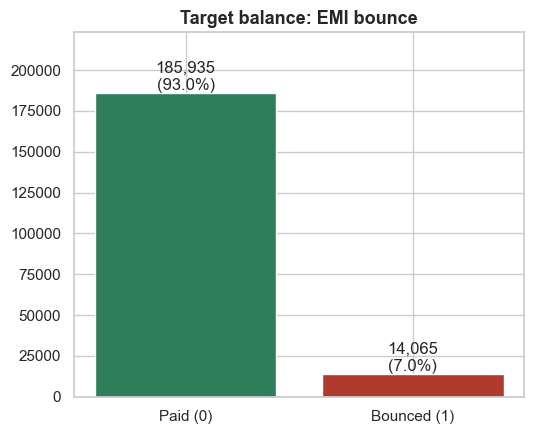

saved images\01_target_balance.png


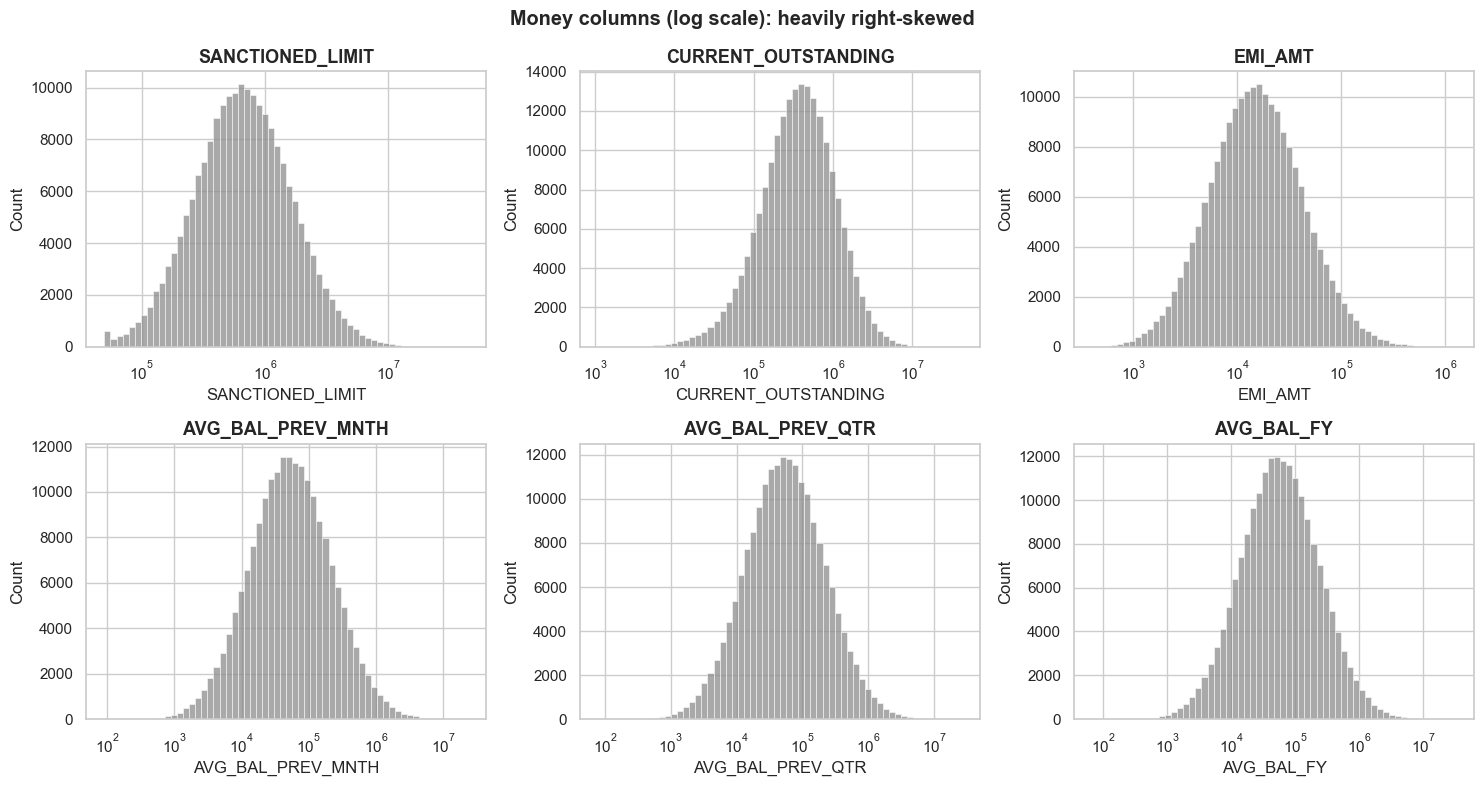

saved images\02_money_histograms.png


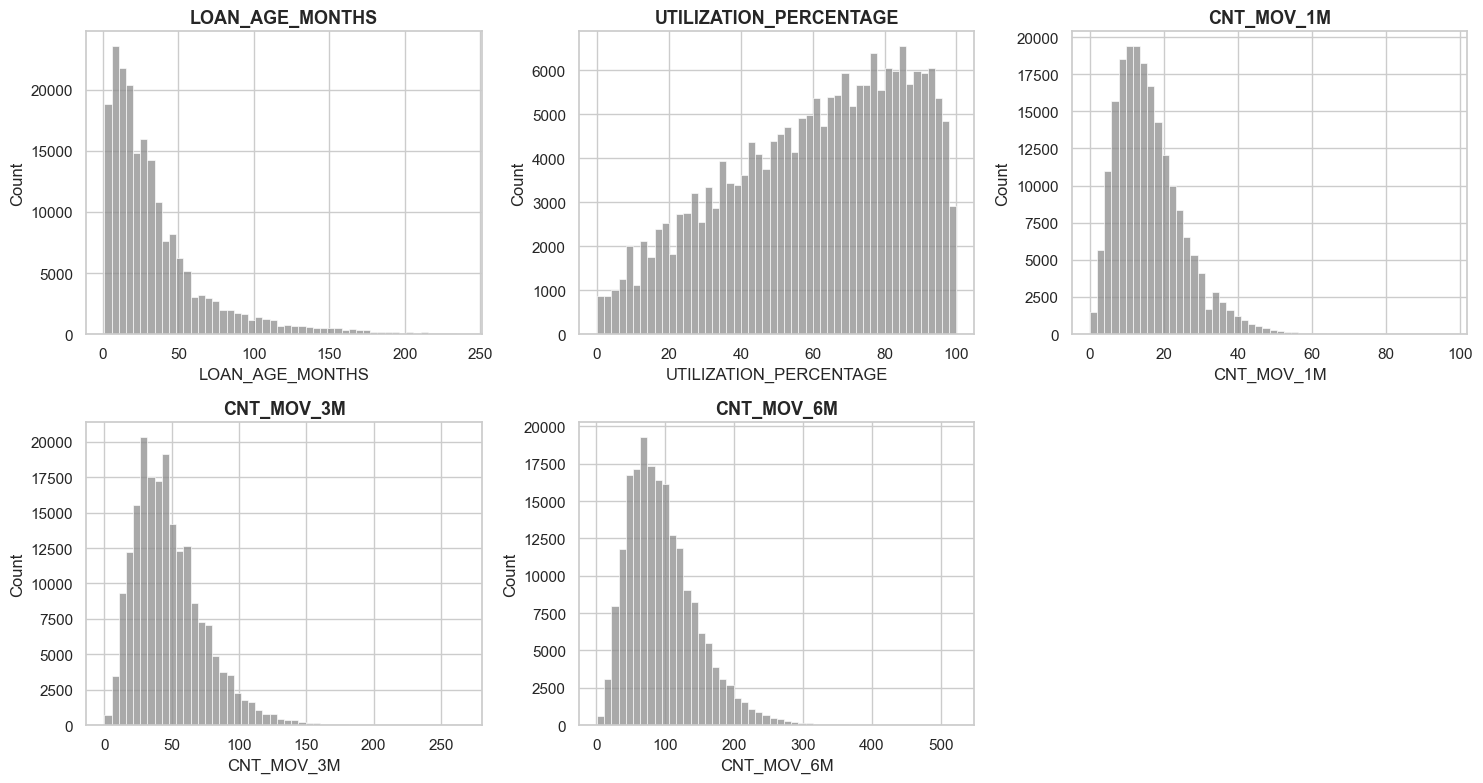

saved images\03_other_histograms.png


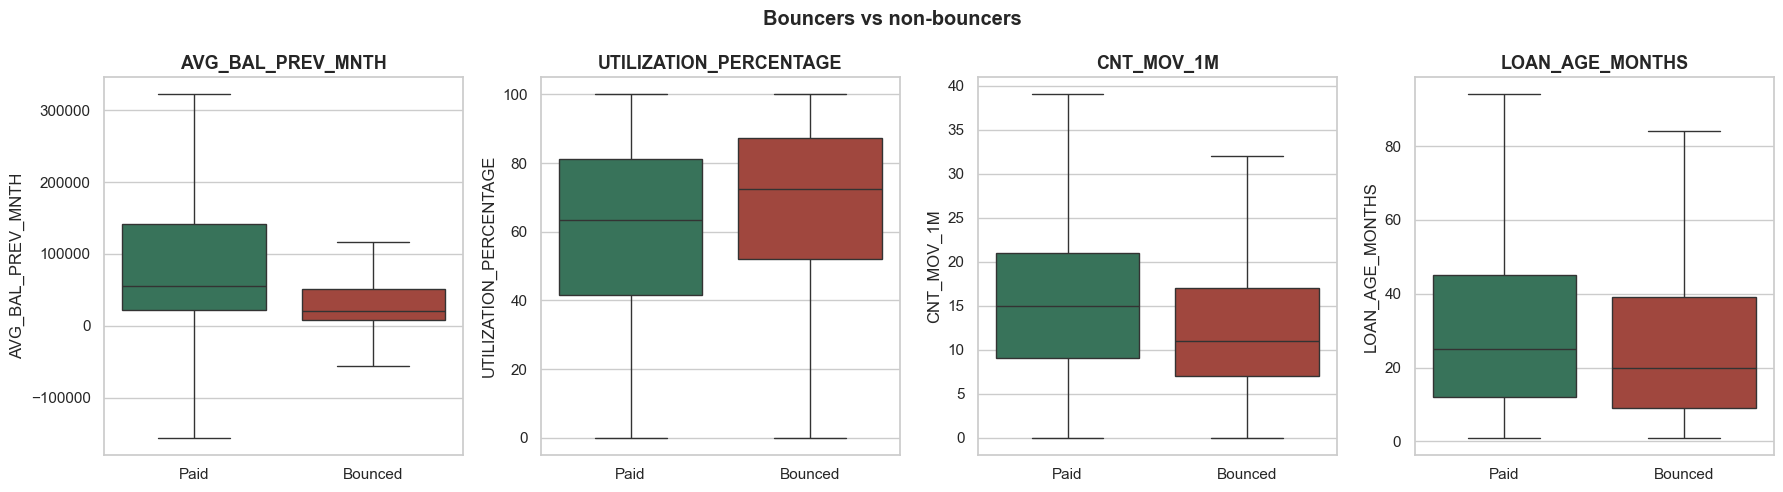

saved images\04_boxplots_by_target.png


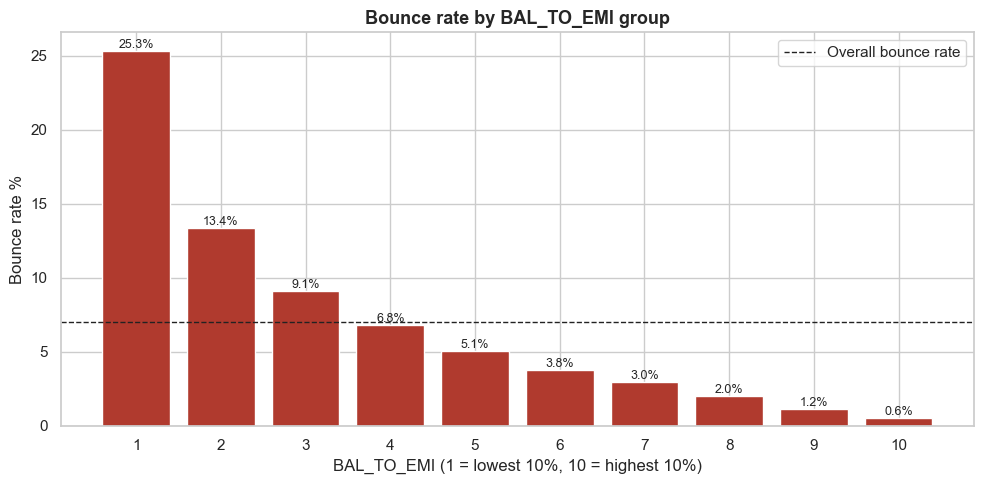

saved images\05_bounce_rate_by_bal_to_emi.png


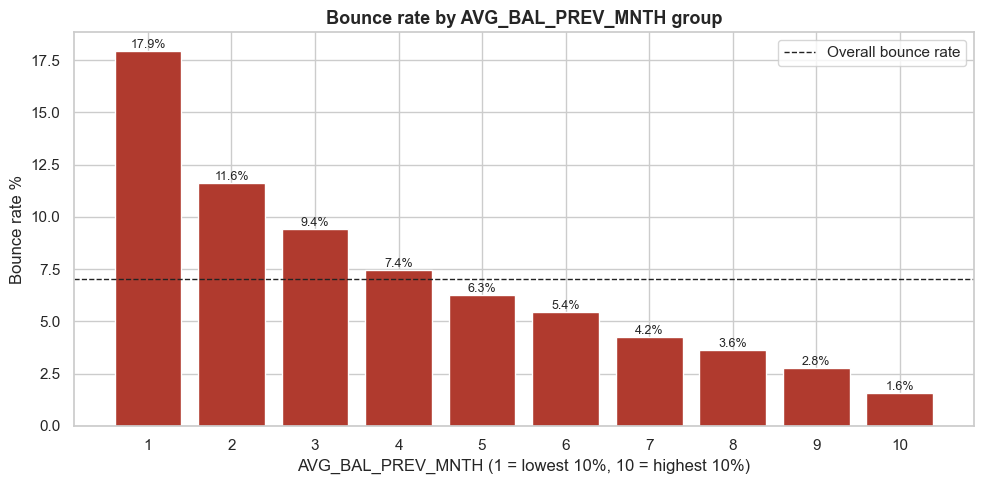

saved images\05b_bounce_rate_by_balance.png


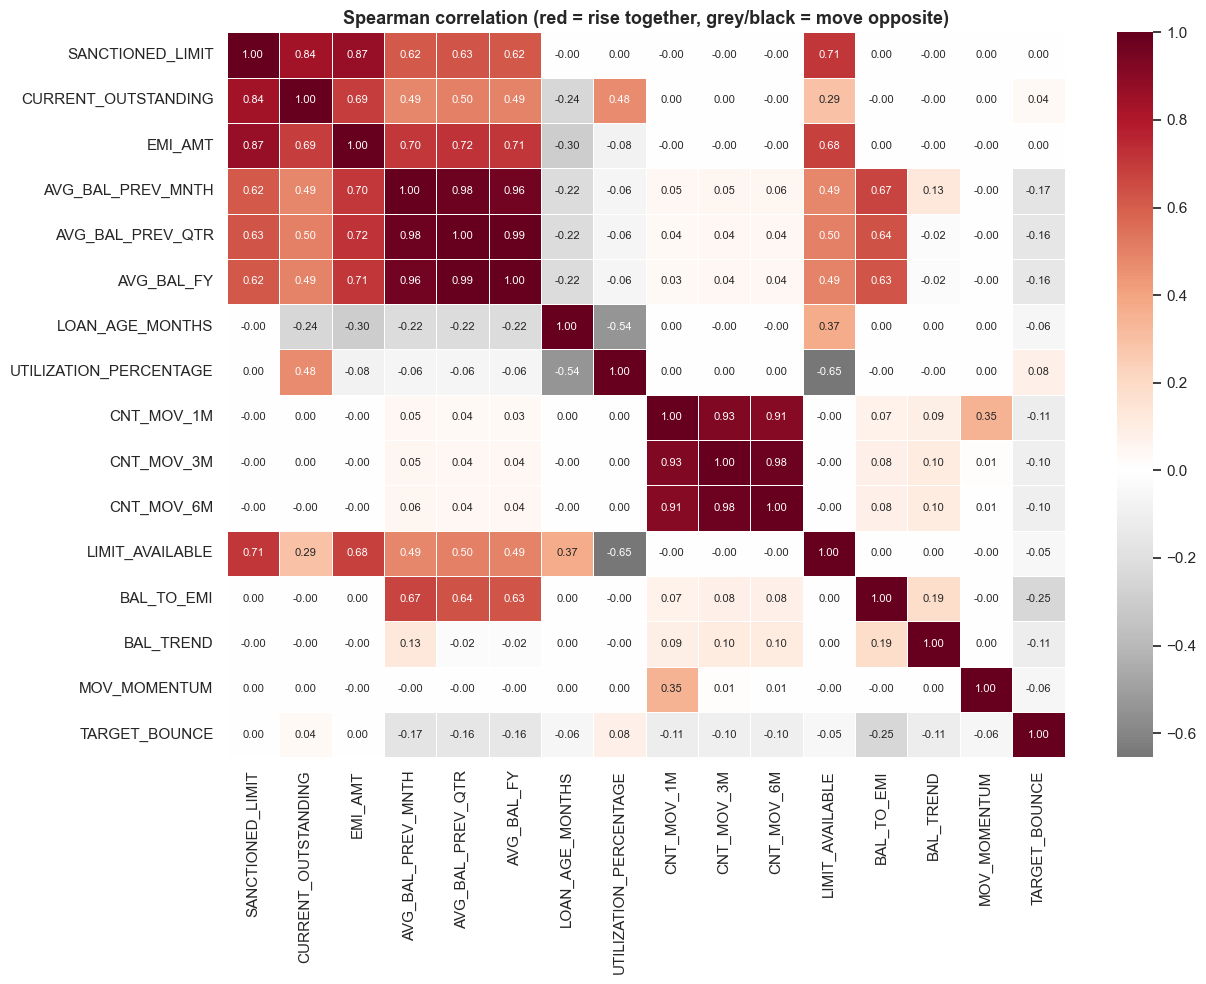

saved images\06_correlation_heatmap.png


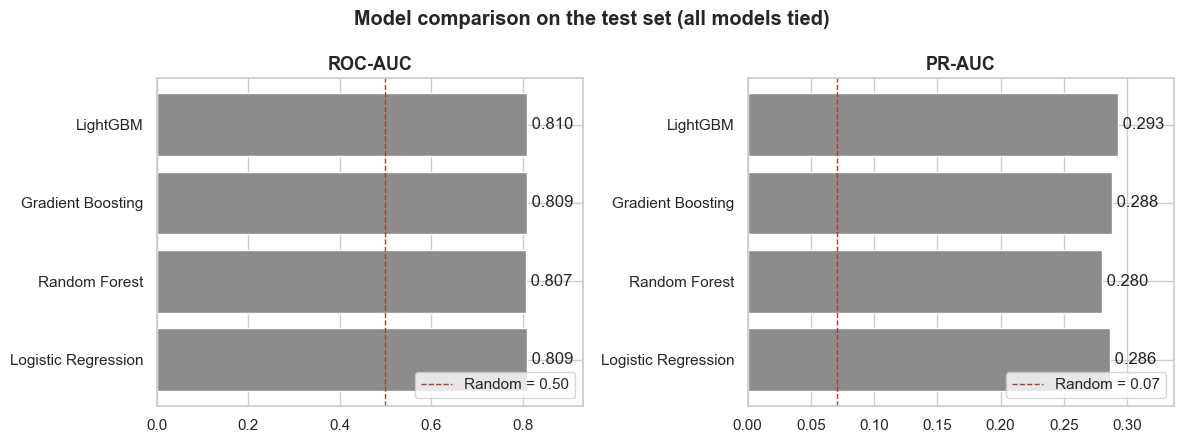

saved images\07_model_comparison.png


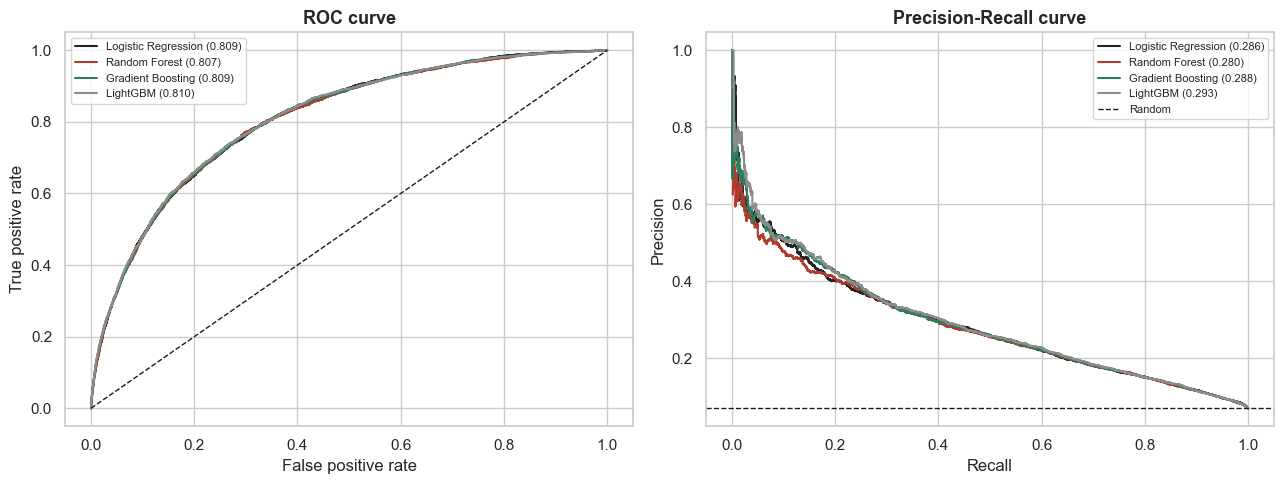

saved images\08_roc_and_pr_curves.png


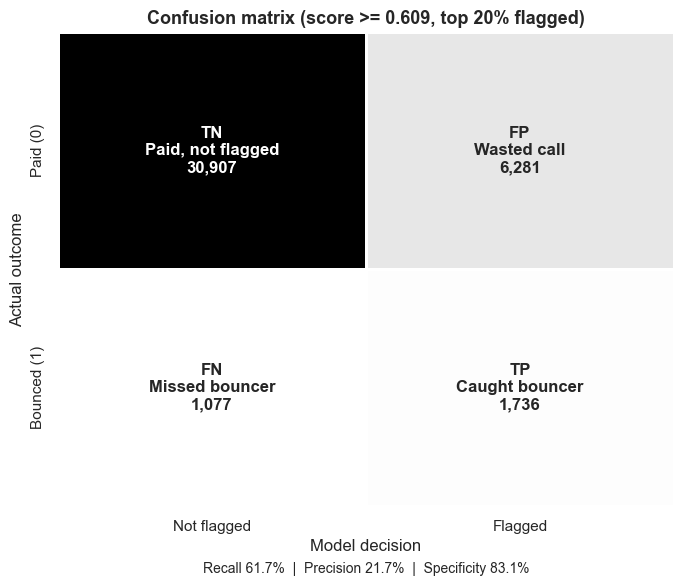

saved images\09_confusion_matrix.png
{'TP': np.int64(1736), 'FP': np.int64(6281), 'FN': np.int64(1077), 'TN': np.int64(30907)}


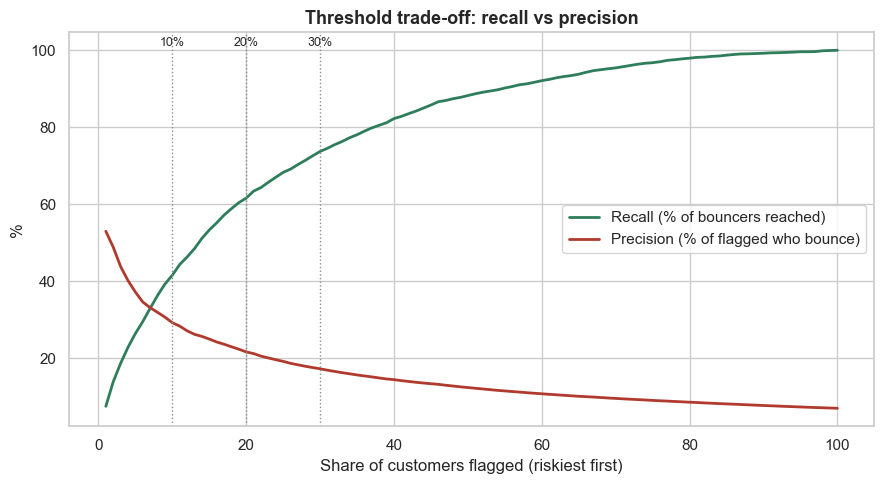

saved images\10_threshold_tradeoff.png


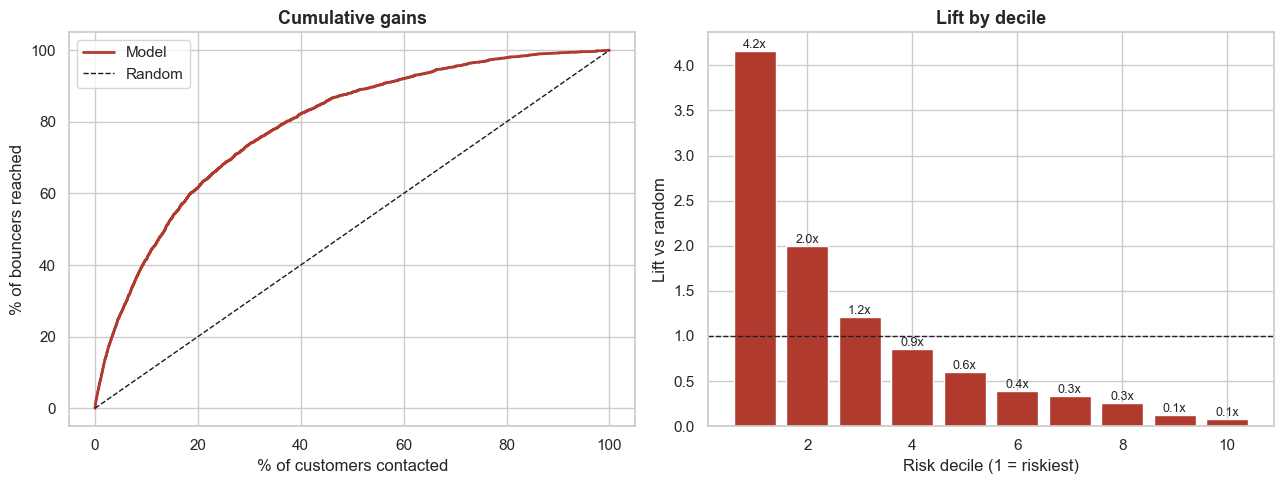

saved images\11_gains_and_lift.png


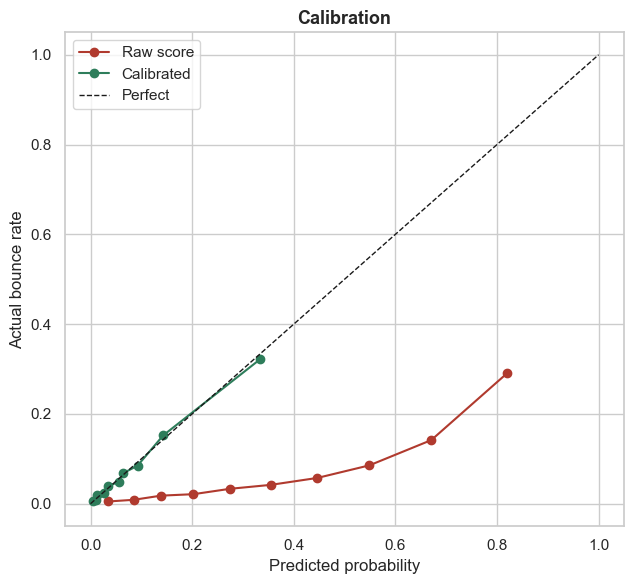

saved images\12_calibration.png


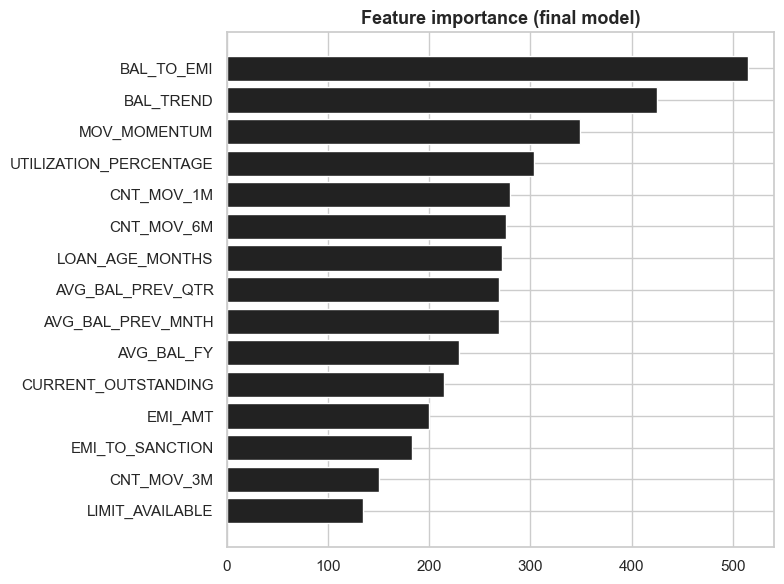

saved images\13_feature_importance.png


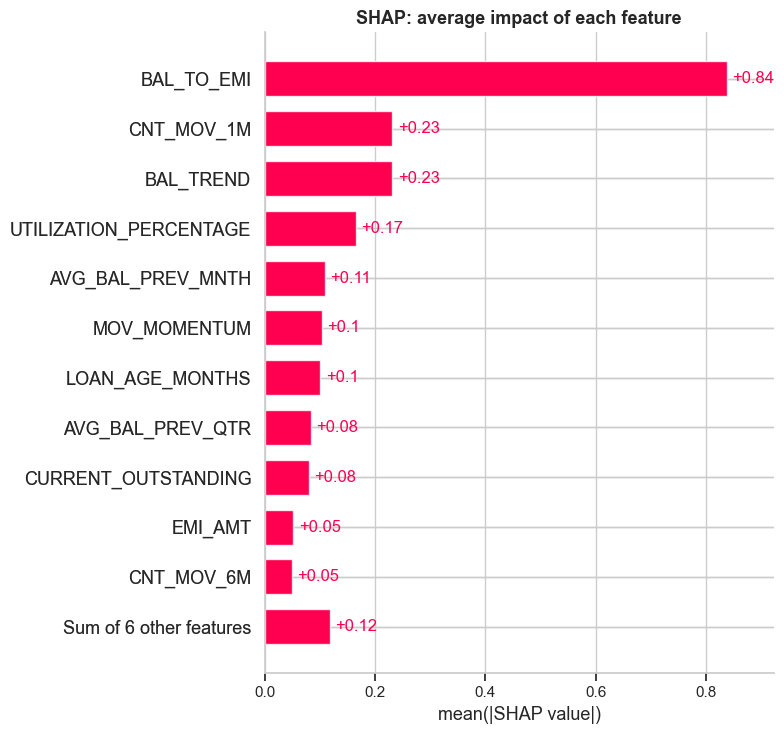

saved images\14_shap_bar.png


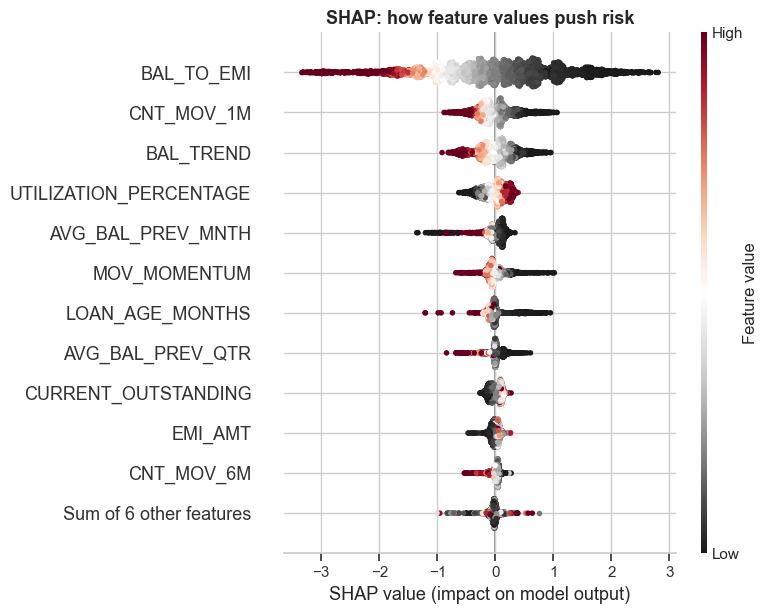

saved images\15_shap_beeswarm.png


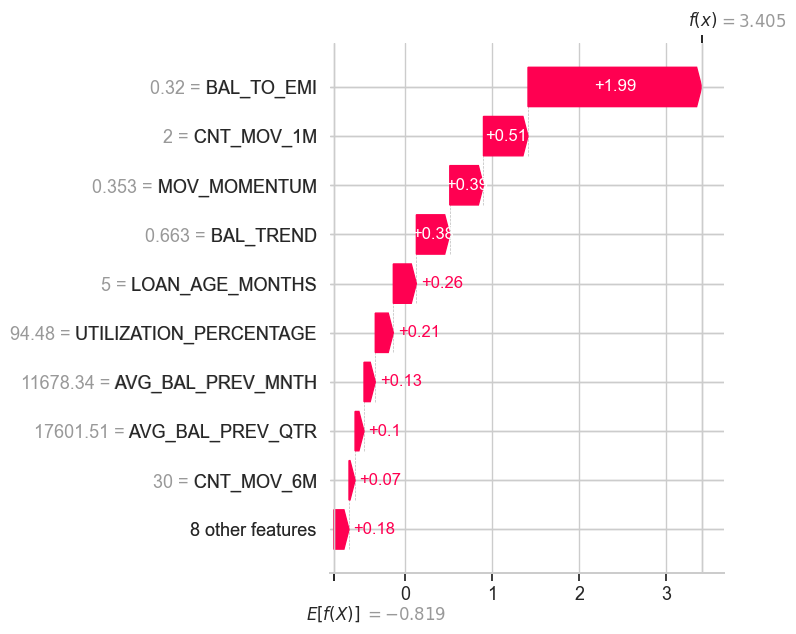

saved images\16_shap_waterfall_riskiest_account.png


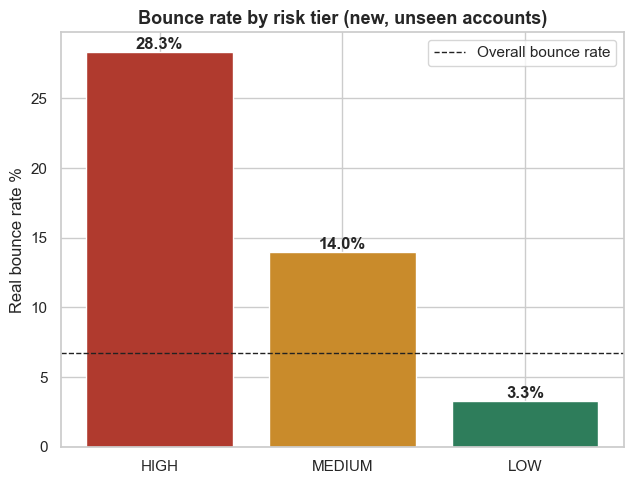

saved images\17_bounce_rate_by_tier.png

All charts saved in the folder: C:\Users\SUMAN\images


In [65]:
import sys
sys.path.append(r"C:\EMI BOUNCE")
import project_charts as pc

pc.make_all(
    df=df,                       # your cleaned data
    d=d,                         # data with the engineered features (BAL_TO_EMI etc.)
    X_test=X_test, y_test=y_test,
    final_model=lgbm_orig,
    models={"Logistic Regression": logreg, "Random Forest": rf,
            "Gradient Boosting": gb, "LightGBM": lgbm_orig},
    features=features,
    p_raw=p_raw, p_cal=p_cal,    # from the calibration step
    cutoff=0.609,
    check=check,                 # optional: new-data results merged with real outcomes
)

In [55]:
# python -m streamlit run app.py